# QAOA - 1D-Ising: Ideal Simulation to Noisy Hardware
## A Reference Tutorial for Future Projects

This notebook is a self-contained walkthrough of the **Quantum Approximate Optimization
Algorithm (QAOA)** applied to a 1D Ising chain, built with Qiskit. It is meant to serve
as a template for future QAOA projects, so every step is explained: the physics, the
circuit construction, the classical optimization loop, and — crucially — how to move
from an *idealized, noiseless* simulation to a *realistic, noisy* one using a snapshot
of real IBM hardware (`FakeBrisbane`) via `AerSimulator`.

**Roadmap:**
1. The physics: an open-chain transverse-field-free Ising Hamiltonian with a longitudinal field
2. The QAOA ansatz circuit (cost layer + mixer layer)
3. Ideal (noiseless) optimization with `qiskit_aer.primitives`
4. Visualizing the ansatz and the optimized probability distribution
5. Building a **noisy** backend from `FakeBrisbane`'s calibration data
6. Re-running the estimator/sampler through the noisy backend (`EstimatorV2` / `SamplerV2`)
7. Comparing ideal vs. noisy results side by side
8. Summary table and notes for extending this template

### 0. Environment

We need three families of tools:
- **`qiskit`** — circuit construction and Pauli operators (`SparsePauliOp`)
- **`qiskit_aer`** — the local, high-performance simulator (`AerSimulator`), plus its
  convenience primitives (`Estimator`, `Sampler`) for *ideal* runs
- **`qiskit_ibm_runtime`** — the primitive interfaces (`EstimatorV2`, `SamplerV2`) that
  we point at a *local, noisy* Aer backend, and `FakeBrisbane`, a fake backend that
  ships with a real calibration snapshot (gate errors, readout errors, coupling map) of
  IBM's `ibm_brisbane` device — no IBM Cloud account or API token required.

`scipy.optimize.minimize` handles the classical outer loop, and `matplotlib` /
`qiskit.visualization` handle plotting.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Ideal (noiseless) primitives - fast, exact statevector-based simulation
from qiskit_aer.primitives import Estimator as AerEstimator, Sampler as AerSampler

# Noisy primitives - route through a real AerSimulator backend
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit_ibm_runtime import EstimatorV2, SamplerV2

print("Environment ready.")

Environment ready.


## 1. The Physics: Open-Chain Ising Model with a Longitudinal Field

We target the cost Hamiltonian

$$
H_C = -\sum_{i=0}^{N-2} Z_i Z_{i+1} \;-\; \sum_{i=0}^{N-1} h_i Z_i,
$$

for $N$ spins/qubits with **open boundary conditions** (no wrap-around term between
qubit $N-1$ and qubit $0$) and *site-dependent* longitudinal fields $h_i$. Minimizing
$\langle H_C\rangle$ over computational basis states $|z\rangle \in \{0,1\}^N$
(with $Z|0\rangle = +|0\rangle$, $Z|1\rangle = -|1\rangle$) is a combinatorial
optimization problem — exactly the kind of problem QAOA is designed to attack.

Below, `n_particles` is $N$, `p` is the number of QAOA layers, and `h_list` holds the
per-site fields $h_i$.

**Note on qubit ordering:** Qiskit uses *little-endian* bit ordering (qubit 0 is the
rightmost bit of a bitstring). `build_cost_ising` builds each Pauli label with qubit 0
on the *left* and then calls `reversed(label)` before joining, so the resulting string
matches Qiskit's convention.

In [5]:
# 1. Problem Setup
n_particles = 3
p = 3          # Number of QAOA layers
h_list = [1, 2, -3]

# 2. Build the cost Hamiltonian: H_C = -sum Z_i Z_{i+1} - sum h_i Z_i
def build_cost_ising(n_particles, h_list):
    pauli_list = []

    # Open-chain interaction terms: -1.0 * Z_i Z_{i+1}
    for i in range(n_particles - 1):
        label = ['I'] * n_particles
        label[i] = 'Z'
        label[i + 1] = 'Z'
        pauli_list.append((''.join(reversed(label)), -1.0))

    # Longitudinal field terms: -h_i * Z_i
    for i in range(n_particles):
        label = ['I'] * n_particles
        label[i] = 'Z'
        pauli_list.append((''.join(reversed(label)), -float(h_list[i])))

    return SparsePauliOp.from_list(pauli_list)

cost_h = build_cost_ising(n_particles, h_list)
print(cost_h)

SparsePauliOp(['IZZ', 'ZZI', 'IIZ', 'IZI', 'ZII'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -2.+0.j,  3.+0.j])


**Reading the output:** each row is a Pauli string paired with its coefficient in
$H_C$. For $N=3$ and `h_list = [1, 2, -3]` we should see two $ZZ$ interaction terms
(`IZZ`, `ZZI`, each with coefficient $-1$) and three single-qubit field terms
(`IIZ`, `IZI`, `ZII` with coefficients $-1, -2, +3$ respectively, i.e. $-h_i$). This is
exactly the `SparsePauliOp` we will hand to the `Estimator` later to compute
$\langle H_C \rangle$ directly, without ever building the $2^N \times 2^N$ matrix.

## 2. The QAOA Ansatz Circuit

For each layer $\ell = 0, \dots, p-1$ we alternate:

- **Cost layer** $U_C(\gamma_\ell) = e^{-i\gamma_\ell H_C}$, implemented gate-by-gate
  since $H_C$ is a sum of commuting $Z$-type Paulis:
  - single-qubit field term $-h_i Z_i \;\to\; R_Z(2\gamma_\ell h_i)$ on qubit $i$
  - two-qubit interaction term $-Z_iZ_{i+1} \;\to\; R_{ZZ}(2\gamma_\ell)$ on qubits $(i, i+1)$
- **Mixer layer** $U_M(\alpha_\ell) = e^{-i\alpha_\ell H_M}$ with $H_M = \sum_i X_i$,
  implemented as $R_X(2\alpha_\ell)$ on every qubit.

The circuit starts each qubit in $|+\rangle$ (via Hadamards) so that the mixer layers can
freely explore the full computational basis. The `params` vector is laid out as
$[\gamma_0, \dots, \gamma_{p-1}, \alpha_0, \dots, \alpha_{p-1}]$, length $2p$.

We add `qc.barrier()` calls purely for **visual clarity** in circuit diagrams — they are
no-ops for simulation and get stripped away during transpilation.

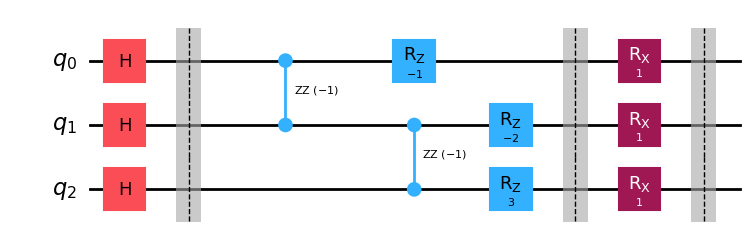

In [6]:
def qaoa_circuit(params, p, cost_h, n_wires):
    '''
    params: 1D array of length 2*p -> [gamma_0..gamma_{p-1}, alpha_0..alpha_{p-1}]
    '''
    gammas = params[:p]
    alphas = params[p:]

    qc = QuantumCircuit(n_wires)

    # Initial state: uniform superposition |+>^{tensor n}
    qc.h(range(n_wires))
    qc.barrier()

    for layer in range(p):
        gamma = gammas[layer]
        alpha = alphas[layer]

        # --- Cost layer: exp(-i * gamma * H_C) ---
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            active_qubits = [i for i, ch in enumerate(reversed(pauli_string)) if ch == 'Z']

            if len(active_qubits) == 1:
                qc.rz(2 * gamma * real_coeff, active_qubits[0])
            elif len(active_qubits) == 2:
                q0, q1 = active_qubits
                qc.rzz(2 * gamma * real_coeff, q0, q1)

        qc.barrier()

        # --- Mixer layer: exp(-i * alpha * H_M),  H_M = sum X_i ---
        for wire in range(n_wires):
            qc.rx(2 * alpha, wire)

        qc.barrier()

    return qc

# Quick visual sanity check with a single layer
demo_params = np.ones(2 * 1) * 0.5
demo_qc = qaoa_circuit(demo_params, p=1, cost_h=cost_h, n_wires=n_particles)
demo_qc.draw(output="mpl")

**Reading the diagram:** one QAOA layer = one cost block (the $R_Z$ and $R_{ZZ}$
gates encoding $H_C$) followed by one mixer block (the layer of $R_X$ gates encoding
$H_M$). Stacking $p$ of these blocks back-to-back is the full ansatz. As $p$ grows the
circuit becomes a better variational approximation to adiabatic evolution (in the limit
$p \to \infty$, QAOA recovers the exact adiabatic ground state), at the cost of more
gates — and, as we will see in Section 5, more exposure to hardware noise.

## 3. Ideal (Noiseless) Optimization

For the classical outer loop, we need a **cost function** $f(\vec\theta) =
\langle \psi(\vec\theta)| H_C |\psi(\vec\theta)\rangle$ that `scipy.optimize.minimize`
can call repeatedly. `qiskit_aer.primitives.Estimator` computes this expectation value
directly from the statevector (no shot noise, no sampling error) — this is our
noiseless baseline.

We use **COBYLA**, a gradient-free method well suited to QAOA's non-smooth landscape
and its typically small number of parameters ($2p$).

In [7]:
# Ideal (noiseless) primitives
ideal_estimator = AerEstimator()
ideal_sampler = AerSampler()

def cost_function_ideal(params):
    '''Exact <H_C> expectation value via the noiseless statevector Estimator.'''
    qc = qaoa_circuit(params, p, cost_h, n_particles)
    job = ideal_estimator.run(qc, cost_h)
    return job.result().values[0]

initial_params = np.ones(2 * p) * 0.5

res_ideal = minimize(
    cost_function_ideal, initial_params, method="COBYLA", options={"maxiter": 150}
)
optimal_params_ideal = res_ideal.x

print(f"Ideal optimum <H_C> = {res_ideal.fun:.6f}")
print(f"Optimal gammas: {optimal_params_ideal[:p]}")
print(f"Optimal alphas: {optimal_params_ideal[p:]}")

Ideal optimum <H_C> = -4.289062
Optimal gammas: [0.24190256 0.47752494 1.57660114]
Optimal alphas: [0.79606174 1.44334801 0.41733263]


**Sanity check:** for `h_list = [1, 2, -3]`, the classical ground state of $H_C$
is easy to find by brute force (only $2^3=8$ states): it is the bitstring that aligns
every spin with its field / coupling preference. The optimizer should land close to
that energy after ~100 COBYLA iterations. If `res_ideal.fun` looks far off, the first
thing to check is whether `p` is large enough — deeper QAOA circuits generally get
closer to the true ground-state energy, at the cost of more parameters to optimize and
(on real hardware) more accumulated gate error.

In [8]:
def get_probabilities_ideal(params):
    '''Full computational-basis probability dictionary from the noiseless Sampler.'''
    qc = qaoa_circuit(params, p, cost_h, n_particles)
    qc.measure_all()
    job = ideal_sampler.run(qc)
    quasi_dists = job.result().quasi_dists[0]
    return {format(state, f"0{n_particles}b"): prob for state, prob in quasi_dists.items()}

probs_ideal = get_probabilities_ideal(optimal_params_ideal)

print("Ideal (noiseless) state probabilities:")
for state, prob in sorted(probs_ideal.items(), key=lambda kv: -kv[1]):
    print(f"  |{state}>: {prob * 100:5.2f}%")

Ideal (noiseless) state probabilities:
  |100>: 57.13%
  |101>: 21.39%
  |000>:  9.28%
  |110>:  4.00%
  |111>:  3.32%
  |011>:  3.03%
  |010>:  1.76%
  |001>:  0.10%


**Reading the output:** the states should be sorted by descending probability. If
QAOA has converged well, one (or a small cluster of degenerate) bitstring(s) should
dominate — that bitstring is QAOA's proposed solution to the optimization problem. We
can cross-check it against the classical ground state of $H_C$ we could compute by
brute-force diagonalization for small $N$.

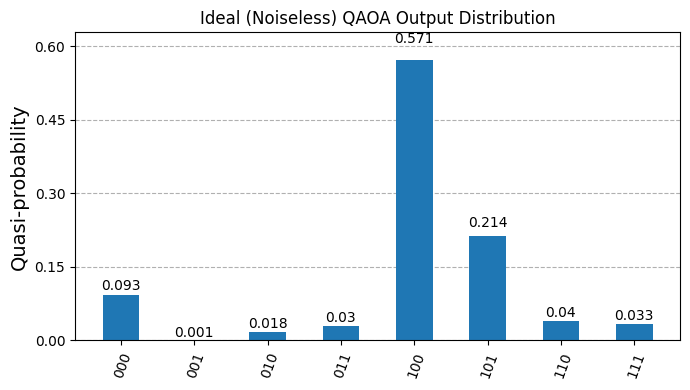

In [9]:
fig_hist, ax_hist = plt.subplots(figsize=(7, 4))
plot_histogram(probs_ideal, title="Ideal (Noiseless) QAOA Output Distribution", ax=ax_hist)
fig_hist.tight_layout()
plt.show()

This histogram is our **noiseless reference**. Everything from here on compares
back to this ideal distribution and the ideal energy `res_ideal.fun`.

## 4. Building a Noisy Backend from Real Hardware Calibration Data

Real quantum devices have imperfect gates and imperfect measurements. Qiskit ships
**fake backends** — snapshots of a real device's calibration data (gate error rates,
$T_1$/$T_2$ relaxation times, readout error, coupling map) — without requiring network
access or an IBM Quantum account. `FakeBrisbane` mirrors `ibm_brisbane`, a 127-qubit
Eagle-generation processor.

The recipe is:
1. Instantiate the fake backend (`FakeBrisbane()`).
2. Extract a `NoiseModel` from it (`NoiseModel.from_backend(...)`).
3. Build a local `AerSimulator` that applies that noise model to every circuit it runs.
4. Wrap that simulator in `EstimatorV2` / `SamplerV2` — the same primitive interfaces
   used for real hardware, so **the rest of your QAOA code barely changes** when you
   eventually swap in a genuine IBM backend.

In [10]:
# 1. Load a local backend snapshot (no account/token required)
backend = FakeBrisbane()
print(f"Simulating target system: {backend.name}  ({backend.num_qubits} qubits)")

# 2. Extract its noise model and build a noisy Aer simulator
noise_model = NoiseModel.from_backend(backend)
backend_sim = AerSimulator(noise_model=noise_model)

# 3. Point the runtime-style primitives at the local noisy simulator
noisy_estimator = EstimatorV2(mode=backend_sim)
noisy_sampler = SamplerV2(mode=backend_sim)

print("Noisy backend ready.")

Simulating target system: fake_brisbane  (127 qubits)
Noisy backend ready.


**Why `EstimatorV2`/`SamplerV2` instead of the Aer primitives here?** The V2
primitives are the same interface used for cloud IBM Runtime jobs. Coding against them
now means that later, switching `mode=backend_sim` to `mode=<real_backend>` (or a
`Session`/`Batch` on real hardware) is a one-line change — nothing else in the
optimization loop needs to be rewritten.

**Important — ISA transpilation:** unlike the Aer `Estimator`/`Sampler` we used in
Section 3 (which happily accept an abstract circuit and Pauli operator built on
`range(n_particles)`), the runtime-style V2 primitives expect circuits that are already
transpiled to the backend's **Instruction Set Architecture (ISA)** — i.e. only the
backend's native basis gates, mapped onto specific *physical* qubits chosen from its
coupling map. If we skip this step, the primitive will raise an error (or silently give
misleading results) because our 3-qubit circuit is not automatically laid out onto the
127-qubit device.

Two things fall out of transpilation that must both be handled:
- the **circuit** gets rewritten into native gates and mapped onto physical qubits, and
- the **observable** (`cost_h`) must be remapped with `.apply_layout(...)` so its Pauli
  terms line up with the *same* physical qubits the transpiler chose.

In [11]:
# Build an ISA-aware transpilation pipeline targeting the noisy backend
pm = generate_preset_pass_manager(backend=backend_sim, optimization_level=1)

def to_isa(qc, observable=None):
    '''Transpile a circuit to the backend ISA, and (optionally) remap an observable
    to the same physical-qubit layout the transpiler chose.'''
    isa_qc = pm.run(qc)
    if observable is None:
        return isa_qc
    isa_obs = observable.apply_layout(isa_qc.layout)
    return isa_qc, isa_obs

# Demo: transpile our p=1 example circuit and inspect the physical-qubit mapping
isa_demo, isa_cost_h_demo = to_isa(demo_qc.remove_final_measurements(inplace=False), cost_h)
print(f"Original circuit: {demo_qc.num_qubits} qubits, depth {demo_qc.depth()}")
print(f"ISA circuit:       {isa_demo.num_qubits} qubits (embedded in {backend.num_qubits}), "
      f"depth {isa_demo.depth()}")

Original circuit: 3 qubits, depth 5
ISA circuit:       3 qubits (embedded in 127), depth 24


**Reading the output:** the ISA circuit reports the *same logical qubit count*
but is embedded in the full device (its two-qubit gates are now native, e.g. `ecr` or
`cz` depending on the backend, and single-qubit rotations become the backend's native
basis, e.g. `rz`/`sx`/`x`). Depth typically increases relative to the abstract circuit
because $R_{ZZ}$ has to be decomposed into the backend's native two-qubit gate plus
single-qubit rotations. This extra depth is exactly what makes noisy execution worse
than the ideal case — more gates means more accumulated error.

## 5. Running the Noisy Pipeline

We now repeat the two things we did in Section 3 — computing $\langle H_C\rangle$ and
sampling the final state — but routed through the noisy `EstimatorV2`/`SamplerV2`.

**A practical note on optimization:** re-running COBYLA against the *noisy* estimator
would be the most realistic simulation of running QAOA on real hardware (and is what
you should do for a real project — see the "Next steps" note at the end). Because noisy
simulation is much slower and this notebook is meant as a fast-running template, here we
instead take a shortcut that is still very informative: we **reuse the parameters we
already optimized on the ideal simulator** (`optimal_params_ideal`) and ask "how much
does the *same* optimized circuit degrade once it's run on noisy hardware?". This
isolates the effect of hardware noise from the effect of the optimizer.

In [12]:
# Build the ISA circuit + observable once, at the ideal-optimal parameters
qc_at_optimum = qaoa_circuit(optimal_params_ideal, p, cost_h, n_particles)
isa_qc_optimum, isa_cost_h = to_isa(qc_at_optimum, cost_h)

# Noisy expectation value <H_C> at the same parameters
job = noisy_estimator.run([(isa_qc_optimum, isa_cost_h)])
noisy_energy = job.result()[0].data.evs

print(f"Ideal   <H_C> at optimum: {res_ideal.fun:.6f}")
print(f"Noisy   <H_C> at same params: {float(noisy_energy):.6f}")
print(f"Absolute degradation: {abs(float(noisy_energy) - res_ideal.fun):.6f}")

Ideal   <H_C> at optimum: -4.289062
Noisy   <H_C> at same params: -3.727539
Absolute degradation: 0.561523


**Reading the output:** the noisy expectation value should be *worse* (higher,
since we are minimizing) than the ideal one — noise pushes the state towards the
maximally-mixed distribution, which raises $\langle H_C \rangle$ back towards zero. The
size of the gap is a rough proxy for "how much hardware error this particular circuit
depth/qubit-count combination is exposed to," and is exactly the kind of number you'd
track if you were deciding whether a given `p` (circuit depth) is still usable on real
hardware.

In [13]:
# Noisy sampling: measure the ISA circuit through the noisy Sampler
isa_qc_meas = isa_qc_optimum.copy()
isa_qc_meas.measure_all()

job2 = noisy_sampler.run([isa_qc_meas], shots=4000)
pub_result = job2.result()[0]
raw_counts = pub_result.data.meas.get_counts()

total_shots = sum(raw_counts.values())
probs_noisy = {bitstring[-n_particles:]: count / total_shots
               for bitstring, count in raw_counts.items()}

print("Noisy state probabilities (FakeBrisbane noise model):")
for state, prob in sorted(probs_noisy.items(), key=lambda kv: -kv[1]):
    print(f"  |{state}>: {prob * 100:5.2f}%")

Noisy state probabilities (FakeBrisbane noise model):
  |100>: 55.30%
  |101>: 20.88%
  |000>:  8.38%
  |110>:  6.28%
  |111>:  4.23%
  |010>:  2.53%
  |011>:  1.50%
  |001>:  0.92%


**Why `bitstring[-n_particles:]`?** After transpilation, `measure_all()` creates
a classical register sized to match however many qubits ended up in the final
measurement, and the returned bitstrings can include ancilla/padding bits from the
device-wide register depending on backend/version. Slicing to the last `n_particles`
characters keeps only the bits corresponding to our logical qubits, in Qiskit's
little-endian convention. Always sanity-check this against a small circuit (as we did
above) before trusting it on a larger one.

## 6. Ideal vs. Noisy: Side-by-Side Comparison

The most useful diagnostic plot for this kind of study is a **grouped bar chart** of the
two probability distributions over the same bitstrings. Divergence between the two bars
for the "winning" bitstring tells you how much confidence to place in a single noisy run
before applying error mitigation.

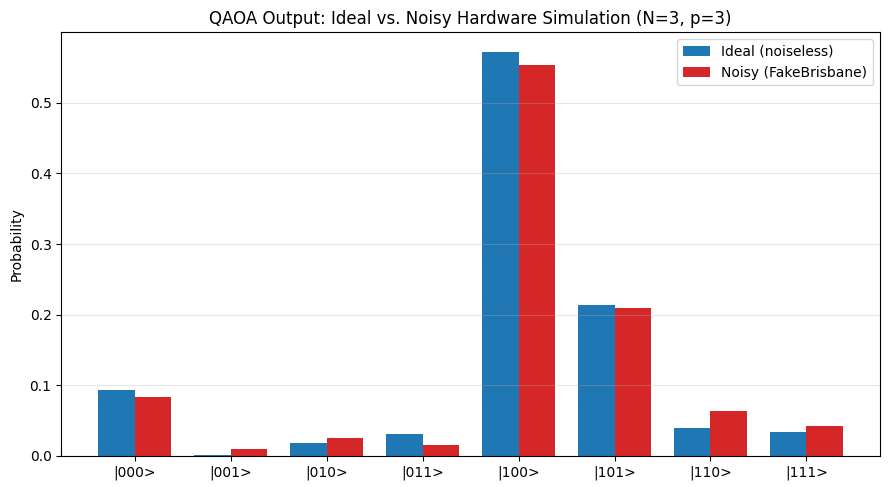

In [14]:
all_states = sorted(set(probs_ideal) | set(probs_noisy))
ideal_vals = [probs_ideal.get(s, 0.0) for s in all_states]
noisy_vals = [probs_noisy.get(s, 0.0) for s in all_states]

x = np.arange(len(all_states))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width / 2, ideal_vals, width, label="Ideal (noiseless)", color="#1f77b4")
ax.bar(x + width / 2, noisy_vals, width, label="Noisy (FakeBrisbane)", color="#d62728")

ax.set_xticks(x)
ax.set_xticklabels([f"|{s}>" for s in all_states])
ax.set_ylabel("Probability")
ax.set_title(f"QAOA Output: Ideal vs. Noisy Hardware Simulation (N={n_particles}, p={p})")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretation:** if the same bitstring still dominates in both bars, the
optimized circuit is *robust* enough at this depth/error-rate combination for the
algorithm's answer to survive noise, even though the confidence (bar height) has
shrunk and probability has leaked into other, sub-optimal, bitstrings. If a *different*
bitstring becomes dominant under noise, that is a red flag that either `p` is too deep
for the current hardware error rates, or that some form of error mitigation
(zero-noise extrapolation, readout-error mitigation, dynamical decoupling, etc.) is
needed before trusting the result.

## 7. Summary Table & Notes for Future Projects

| Step | Ideal pipeline | Noisy pipeline |
|---|---|---|
| Circuit | `qaoa_circuit(...)` on `range(n_particles)` | same, then `pm.run(...)` to map onto backend ISA |
| Observable | `cost_h` as-is | `cost_h.apply_layout(isa_qc.layout)` |
| Estimator | `qiskit_aer.primitives.Estimator()` | `qiskit_ibm_runtime.EstimatorV2(mode=backend_sim)` |
| Sampler | `qiskit_aer.primitives.Sampler()` | `qiskit_ibm_runtime.SamplerV2(mode=backend_sim)` |
| Run call | `estimator.run(qc, cost_h)` | `estimator.run([(isa_qc, isa_cost_h)])` |
| Result access | `.result().values[0]` | `.result()[0].data.evs` |
| Shots | exact (statevector) | must specify `shots=` explicitly |

**Ideas for extending this template:**
- **Optimize directly against noise:** replace `cost_function_ideal` with a version
  that calls `noisy_estimator`, and re-run `minimize(...)`. This is the realistic
  workflow for a hardware-targeted project, at the cost of much slower iterations
  (consider `maxiter` reduction and/or a coarser optimizer during development).
- **Sweep circuit depth `p`:** loop over several values of `p`, re-optimize at each,
  and plot ideal-vs-noisy energy gap as a function of `p` — this quantifies exactly
  where noise starts to dominate over the algorithmic benefit of extra layers, echoing
  the same "compilation cost vs. hardware fidelity" trade-off explored in the
  Cliffordized-Trotter benchmarking notebook.
- **Swap in a real backend:** once satisfied with `backend_sim`, replace it with a
  `QiskitRuntimeService` backend and a `Session`/`Batch` — the estimator/sampler
  call sites are unchanged.
- **Error mitigation:** `EstimatorV2` exposes `options.resilience_level` (readout-error
  mitigation, ZNE, etc.) when run against real IBM Runtime backends; worth revisiting
  once this template is pointed at real hardware.
- **Larger problem sizes:** for $N \gtrsim 15$–20, exact statevector simulation
  (the ideal `Estimator`) becomes intractable; that is precisely where techniques like
  MPS/tensor-network simulation or Clifford-proxy benchmarking (see other notebooks in
  this project) become the only way to sanity-check circuit behavior before hardware
  execution.


In [ ]:
from qiskit.quantum_info import SparsePauliOp

def build_cost_bose(n_particles, J_xy, J_z, h_list):
    """
    Builds a Hamiltonian for a Bose-type 1D chain:
    H_C = - J_xy * sum(X_i X_{i+1} + Y_i Y_{i+1}) - J_z * sum(Z_i Z_{i+1}) - sum(h_i Z_i)
    """
    pauli_list = []

    for i in range(n_particles - 1):
        # XX term
        label_x = ['I'] * n_particles
        label_x[i] = 'X'
        label_x[i + 1] = 'X'
        pauli_list.append((''.join(reversed(label_x)), -float(J_xy)))

        # YY term
        label_y = ['I'] * n_particles
        label_y[i] = 'Y'
        label_y[i + 1] = 'Y'
        pauli_list.append((''.join(reversed(label_y)), -float(J_xy)))

        # ZZ term
        label_z = ['I'] * n_particles
        label_z[i] = 'Z'
        label_z[i + 1] = 'Z'
        pauli_list.append((''.join(reversed(label_z)), -float(J_z)))

    # Longitudinal field terms: -h_i * Z_i
    for i in range(n_particles):
        label = ['I'] * n_particles
        label[i] = 'Z'
        pauli_list.append((''.join(reversed(label)), -float(h_list[i])))

    return SparsePauliOp.from_list(pauli_list)

# Example usage:
n_particles = 3
cost_h = build_cost_bose(n_particles, J_xy=1.0, J_z=0.5, h_list=[1, 2, -3])

In [ ]:
def qaoa_bose_circuit(params, p, cost_h, n_wires):
    gammas = params[:p]
    alphas = params[p:]

    qc = QuantumCircuit(n_wires)

    # Initial superposition |+>^N
    qc.h(range(n_wires))
    qc.barrier()

    for layer in range(p):
        gamma = gammas[layer]
        alpha = alphas[layer]

        # --- Cost Layer ---
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            # Note string indexing matching Qiskit little-endian format
            reversed_str = list(reversed(pauli_string))
            active_qubits = [i for i, ch in enumerate(reversed_str) if ch != 'I']
            pauli_types = [reversed_str[i] for i in active_qubits]

            if len(active_qubits) == 1 and pauli_types[0] == 'Z':
                qc.rz(2 * gamma * real_coeff, active_qubits[0])

            elif len(active_qubits) == 2:
                q0, q1 = active_qubits
                term = "".join(pauli_types)
                if term == "ZZ":
                    qc.rzz(2 * gamma * real_coeff, q0, q1)
                elif term == "XX":
                    qc.rxx(2 * gamma * real_coeff, q0, q1)
                elif term == "YY":
                    qc.ryy(2 * gamma * real_coeff, q0, q1)

        qc.barrier()

        # --- Mixer Layer ---
        for wire in range(n_wires):
            qc.rx(2 * alpha, wire)

        qc.barrier()

    return qc

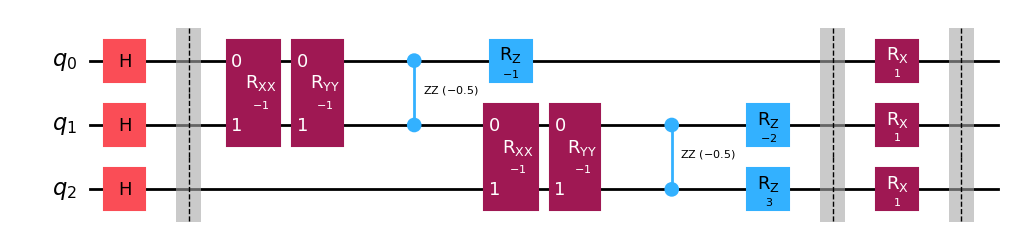

In [18]:
# Quick visual sanity check with a single layer
demo_params_bose = np.ones(2 * 1) * 0.5
demo_qc_bose = qaoa_bose_circuit(demo_params, p=1, cost_h=cost_h, n_wires=n_particles)
demo_qc_bose.draw(output="mpl")

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Global or outer lists to log history
iteration_history_ideal = []
iteration_history_noisy = []

def get_cost_function(circuit_fn, cost_op, estimator, history_list):
    """
    Returns an objective function for scipy.optimize.minimize, 
    logging each calculated expectation value to history_list.
    """
    def cost_func(params):
        # Generate circuit instance for current params
        qc = circuit_fn(params)
        
        # Run Estimator pub
        job = estimator.run([(qc, cost_op)])
        result = job.result()[0]
        
        # Extract expectation value <H_C>
        energy = float(result.data.evs)
        
        # Log energy to track iterations
        history_list.append(energy)
        return energy

    return cost_func

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Qiskit Core & Aer Primitives
from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

# Fake Backend & Transpiler
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# --- 1. Setup Backends & Primitives ---
# Ideal Reference Primitive (Exact Statevector)
ideal_estimator = StatevectorEstimator()

# Noisy Backend Setup via Aer
fake_backend = FakeBrisbane()
print(f"Simulating target system: {fake_backend.name} ({fake_backend.num_qubits} qubits)")

# 1. Setup noise model and Aer simulator
noise_model = NoiseModel.from_backend(fake_backend)
backend_sim = AerSimulator(noise_model=noise_model)

# Noisy Primitive tied to the local simulator
noisy_estimator = AerEstimatorV2(
    options={"backend_options": {"noise_model": noise_model}}
)

# Pass Manager for hardware transpilation targeting Brisbane
pm = generate_preset_pass_manager(optimization_level=3, backend=fake_backend)
print("Noisy backend ready.")

Simulating target system: fake_brisbane (127 qubits)
Noisy backend ready.


In [27]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

def qaoa_bose_circuit_template(p, cost_h, n_wires):
    """
    Creates a parameterized QAOA circuit template for a Bose-type system.
    Uses ParameterVectors for gammas and alphas.
    """
    gammas = ParameterVector('gamma', p)
    alphas = ParameterVector('alpha', p)

    qc = QuantumCircuit(n_wires)

    # Initial Hadamard state |+>^N
    qc.h(range(n_wires))
    qc.barrier()

    for layer in range(p):
        gamma = gammas[layer]
        alpha = alphas[layer]

        # Cost Layer evolution
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            reversed_str = list(reversed(pauli_string))
            active_qubits = [i for i, ch in enumerate(reversed_str) if ch != 'I']
            pauli_types = [reversed_str[i] for i in active_qubits]

            if len(active_qubits) == 1 and pauli_types[0] == 'Z':
                qc.rz(2 * gamma * real_coeff, active_qubits[0])
            elif len(active_qubits) == 2:
                q0, q1 = active_qubits
                term = "".join(pauli_types)
                if term == "ZZ":
                    qc.rzz(2 * gamma * real_coeff, q0, q1)
                elif term == "XX":
                    qc.rxx(2 * gamma * real_coeff, q0, q1)
                elif term == "YY":
                    qc.ryy(2 * gamma * real_coeff, q0, q1)

        qc.barrier()

        # Mixer Layer evolution (RX rotations)
        for wire in range(n_wires):
            qc.rx(2 * alpha, wire)

        qc.barrier()

    return qc

In [ ]:
# Quick visual sanity check with a single layer
demo_params_bose = np.ones(2 * 1) * 0.5
demo_qc_bose = qaoa_bose_circuit_template(demo_params, p=1, cost_h=cost_h, n_wires=n_particles)
demo_qc_bose.draw(output="mpl")

In [28]:
history_ideal = []
history_noisy = []

def make_cost_function(circuit_template, cost_op, estimator, pass_manager, history_list):
    """
    Creates an objective function that transpiles the ansatz to the target layout
    and logs energy values per iteration step.
    """
    # Pre-transpile the parametric circuit topology for FakeBrisbane layout
    if pass_manager is not None:
        transpiled_circuit = pass_manager.run(circuit_template)
        # Map the Hamiltonian to the physical layout chosen by the transpiler
        layout = transpiled_circuit.layout
        mapped_cost_op = cost_op.apply_layout(layout)
    else:
        transpiled_circuit = circuit_template
        mapped_cost_op = cost_op

    def cost_func(params):
        # Assign current numeric parameters to the circuit
        bound_circuit = transpiled_circuit.assign_parameters(params)
        
        # Execute primitive PUB: (circuit, observable)
        job = estimator.run([(bound_circuit, mapped_cost_op)])
        result = job.result()[0]
        
        # Extract mean value <H_C>
        energy = float(result.data.evs)
        history_list.append(energy)
        return energy

    return cost_func

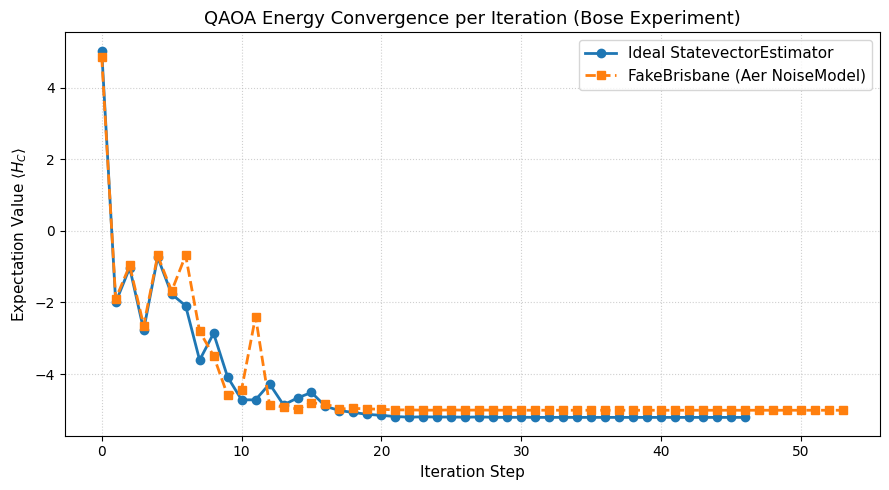

In [29]:
# Setup initial parameters for p=1 QAOA layer
p = 1
np.random.seed(42)
initial_params = np.random.uniform(0, 2 * np.pi, 2 * p)

# Create parameterized QAOA template circuit
qaoa_template = qaoa_bose_circuit_template(p, cost_h, n_particles)

# 1. Ideal Optimization (Statevector)
cost_fn_ideal = make_cost_function(
    circuit_template=qaoa_template,
    cost_op=cost_h,
    estimator=ideal_estimator,
    pass_manager=None,
    history_list=history_ideal
)
res_ideal = minimize(cost_fn_ideal, initial_params, method='COBYLA')

# 2. Noisy Optimization (FakeBrisbane via Aer)
cost_fn_noisy = make_cost_function(
    circuit_template=qaoa_template,
    cost_op=cost_h,
    estimator=noisy_estimator,
    pass_manager=pm,
    history_list=history_noisy
)
res_noisy = minimize(cost_fn_noisy, initial_params, method='COBYLA')

# --- Plot Iteration Progression ---
plt.figure(figsize=(9, 5))
plt.plot(history_ideal, label='Ideal StatevectorEstimator', marker='o', color='#1f77b4', linewidth=2)
plt.plot(history_noisy, label='FakeBrisbane (Aer NoiseModel)', marker='s', color='#ff7f0e', linestyle='--', linewidth=2)

plt.title("QAOA Energy Convergence per Iteration (Bose Experiment)", fontsize=13)
plt.xlabel("Iteration Step", fontsize=11)
plt.ylabel("Expectation Value $\\langle H_C \\rangle$", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Target system: fake_brisbane (127 qubits)


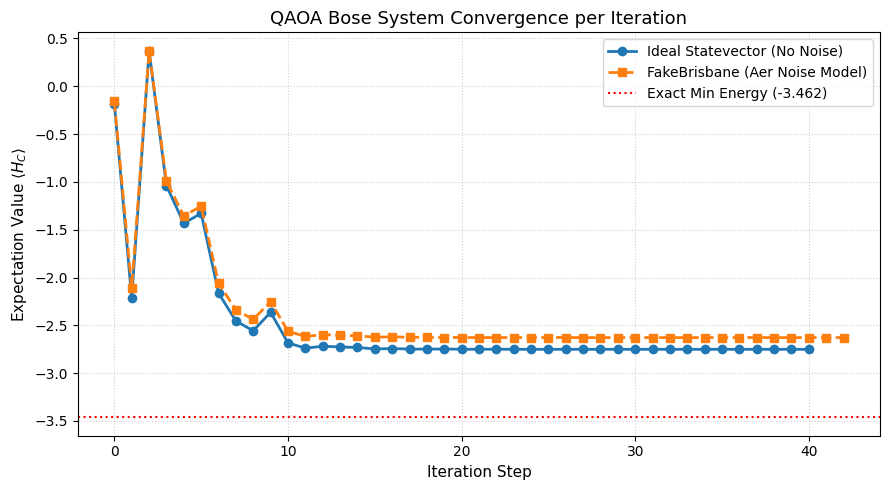

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp

# Primitives & Simulator Engines
from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

# Fake Backend & Transpiler
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager


# --- 1. Build Bose Cost Hamiltonian ---
def build_cost_bose(n_particles, J_xy, J_z, h_list):
    """
    Builds a Hamiltonian for a 1D Bose interaction chain:
    H_C = - J_xy * sum(X_i X_{i+1} + Y_i Y_{i+1}) - J_z * sum(Z_i Z_{i+1}) - sum(h_i Z_i)
    """
    pauli_list = []
    for i in range(n_particles - 1):
        # XX interaction (Particle tunneling/hopping)
        label_x = ['I'] * n_particles
        label_x[i] = 'X'
        label_x[i + 1] = 'X'
        pauli_list.append((''.join(reversed(label_x)), -float(J_xy)))

        # YY interaction (Particle tunneling/hopping)
        label_y = ['I'] * n_particles
        label_y[i] = 'Y'
        label_y[i + 1] = 'Y'
        pauli_list.append((''.join(reversed(label_y)), -float(J_xy)))

        # ZZ interaction (On-site / Nearest-neighbor interaction)
        label_z = ['I'] * n_particles
        label_z[i] = 'Z'
        label_z[i + 1] = 'Z'
        pauli_list.append((''.join(reversed(label_z)), -float(J_z)))

    # On-site potential terms: -h_i * Z_i
    for i in range(n_particles):
        label = ['I'] * n_particles
        label[i] = 'Z'
        pauli_list.append((''.join(reversed(label)), -float(h_list[i])))

    return SparsePauliOp.from_list(pauli_list)


# --- 2. Build QAOA Parameterized Circuit Template ---
def qaoa_bose_circuit_template(p, cost_h, n_wires):
    """
    Creates a symbolic QAOA ansatz using ParameterVectors for gammas and alphas.
    """
    gammas = ParameterVector('gamma', p)
    alphas = ParameterVector('alpha', p)

    qc = QuantumCircuit(n_wires)
    qc.h(range(n_wires))  # Initial state |+>^N
    qc.barrier()

    for layer in range(p):
        gamma = gammas[layer]
        alpha = alphas[layer]

        # Cost Layer Evolution: exp(-i * gamma * H_C)
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            reversed_str = list(reversed(pauli_string))
            active_qubits = [i for i, ch in enumerate(reversed_str) if ch != 'I']
            pauli_types = [reversed_str[i] for i in active_qubits]

            if len(active_qubits) == 1 and pauli_types[0] == 'Z':
                qc.rz(2 * gamma * real_coeff, active_qubits[0])
            elif len(active_qubits) == 2:
                q0, q1 = active_qubits
                term = "".join(pauli_types)
                if term == "ZZ":
                    qc.rzz(2 * gamma * real_coeff, q0, q1)
                elif term == "XX":
                    qc.rxx(2 * gamma * real_coeff, q0, q1)
                elif term == "YY":
                    qc.ryy(2 * gamma * real_coeff, q0, q1)

        qc.barrier()

        # Mixer Layer Evolution: exp(-i * alpha * H_M)
        for wire in range(n_wires):
            qc.rx(2 * alpha, wire)

        qc.barrier()

    return qc

# --- 3. Objective Function Factory ---
def make_cost_function(circuit_template, cost_op, estimator, pass_manager, history_list):
    """
    Transpiles ansatz to backend layout once, then evaluates <H_C> 
    at each iteration step.
    """
    if pass_manager is not None:
        transpiled_circuit = pass_manager.run(circuit_template)
        mapped_cost_op = cost_op.apply_layout(transpiled_circuit.layout)
    else:
        transpiled_circuit = circuit_template
        mapped_cost_op = cost_op

    def cost_func(params):
        bound_circuit = transpiled_circuit.assign_parameters(params)
        job = estimator.run([(bound_circuit, mapped_cost_op)])
        result = job.result()[0]
        energy = float(result.data.evs)
        history_list.append(energy)
        return energy

    return cost_func


# --- 4. Main Execution ---

# Experiment setup
n_particles = 3
p = 1  # 1 layer of QAOA
cost_h = build_cost_bose(n_particles, J_xy=1.0, J_z=0.5, h_list=[1.0, 0.5, -1.0])

# Instantiate primitives
ideal_estimator = StatevectorEstimator()

fake_backend = FakeBrisbane()
print(f"Target system: {fake_backend.name} ({fake_backend.num_qubits} qubits)")

noise_model = NoiseModel.from_backend(fake_backend)
backend_sim = AerSimulator(noise_model=noise_model)
noisy_estimator = AerEstimatorV2(
    options={"backend_options": {"noise_model": noise_model}}
)

pm = generate_preset_pass_manager(optimization_level=3, backend=fake_backend)

# Optimization initial state
np.random.seed(42)
initial_params = np.random.uniform(0, 2 * np.pi, 2 * p)

history_ideal = []
history_noisy = []

qaoa_template = qaoa_bose_circuit_template(p, cost_h, n_particles)
qaoa_template.draw("mpl", fold=False)

# Run Ideal Optimization
cost_fn_ideal = make_cost_function(qaoa_template, cost_h, ideal_estimator, None, history_ideal)
res_ideal = minimize(cost_fn_ideal, initial_params, method='COBYLA')

# Run Noisy Optimization (FakeBrisbane Aer Simulation)
cost_fn_noisy = make_cost_function(qaoa_template, cost_h, noisy_estimator, pm, history_noisy)
res_noisy = minimize(cost_fn_noisy, initial_params, method='COBYLA')

# Track Exact Ground State for Reference
exact_ground_energy = min(np.linalg.eigvalsh(cost_h.to_matrix()))

# --- 5. Convergence Plotting ---
plt.figure(figsize=(9, 5))
plt.plot(history_ideal, label='Ideal Statevector (No Noise)', marker='o', color='#1f77b4', linewidth=2)
plt.plot(history_noisy, label='FakeBrisbane (Aer Noise Model)', marker='s', color='#ff7f0e', linestyle='--', linewidth=2)
plt.axhline(y=exact_ground_energy, color='r', linestyle=':', label=f'Exact Min Energy ({exact_ground_energy:.3f})')

plt.title("QAOA Bose System Convergence per Iteration", fontsize=13)
plt.xlabel("Iteration Step", fontsize=11)
plt.ylabel("Expectation Value $\\langle H_C \\rangle$", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()